# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [2]:
# Lectura datos, relación variables, mapas de correlación...
df = pd.read_csv('data/Advertising.csv')
df.head(25)

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0
5,5,8.7,48.9,75.0,7200.0
6,6,57.5,32.8,23.5,11800.0
7,7,120.2,19.6,11.6,13200.0
8,8,8.6,2.1,1.0,4800.0
9,9,199.8,2.6,21.2,10600.0


In [3]:
print(df.loc[0, 'newpaper'])
print(df['newpaper'].dtype)

6s9.2
object


In [4]:
df.loc[0, 'newpaper'] = df.loc[0, 'newpaper'].replace('s', '')
df['newpaper'] = df['newpaper'].astype(float)

In [5]:
# Utiliza todas las celdas que necesites...
#quitamos la columna unnamed: 0

df = df.drop(columns=['Unnamed: 0'])
df.head()

,TV,radio,newpaper,sales
0,230.1,37.8,69.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    float64
 3   sales     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [7]:
df.describe()

,TV,radio,newpaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


In [8]:
corr_matrix = df.corr(numeric_only=True)

print(corr_matrix)


                TV     radio  newpaper     sales
TV        1.000000  0.054809  0.056648  0.782224
radio     0.054809  1.000000  0.354104  0.576223
newpaper  0.056648  0.354104  1.000000  0.228299
sales     0.782224  0.576223  0.228299  1.000000


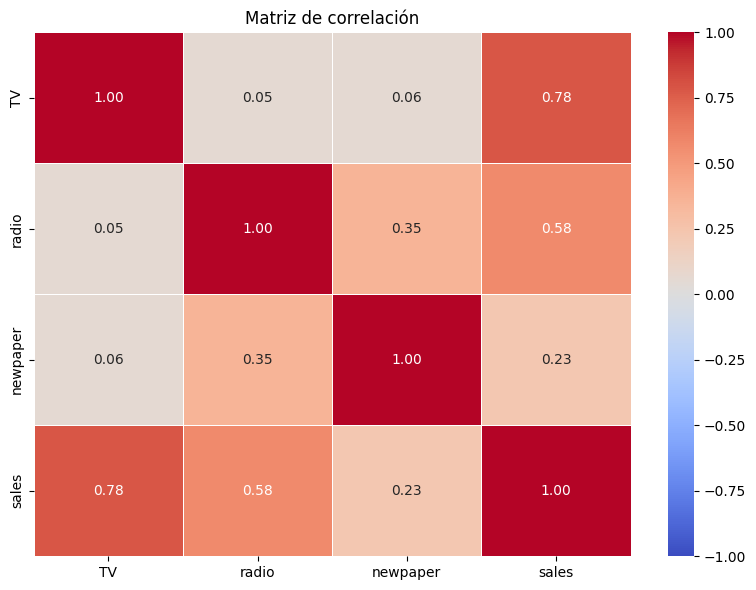

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,       # Mostrar valores de correlación
    cmap='coolwarm',  # Paleta de colores
    fmt='.2f',        # Dos decimales
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

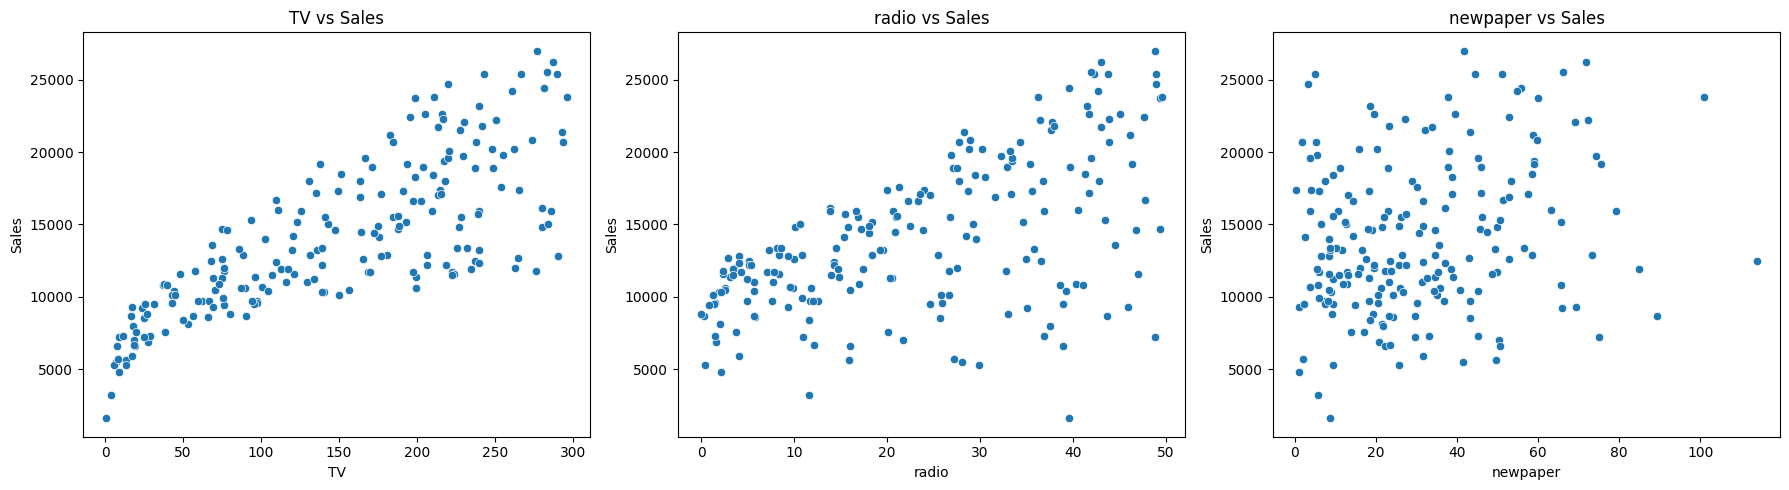

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = ['TV', 'radio', 'newpaper']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, variable in enumerate(variables):
    sns.scatterplot(
        data=df,
        x=variable,
        y='sales',
        ax=axes[i]
    )

    axes[i].set_title(f'{variable} vs Sales')
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel('Sales')

plt.tight_layout()
plt.show()

## Modelado

In [11]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.
X = df[['TV', 'radio', 'newpaper']]
y = df['sales']

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [13]:
from sklearn.linear_model import LinearRegression

# Crear el modelo
lr = LinearRegression()

# Entrenar
lr.fit(X_train, y_train)

# Predicciones
y_pred_test_lr = lr.predict(X_test)
y_pred_train_lr = lr.predict(X_train)

In [14]:
print("Intercept:", lr.intercept_)

for variable, coef in zip(X.columns, lr.coef_):
    print(f"{variable}: {coef:.4f}")

Intercept: 2979.067338122628
TV: 44.7295
radio: 189.1951
newpaper: 2.7611


In [15]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

def evaluar_modelo(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)

    return {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    }

resultados_test_lr = evaluar_modelo(y_test, y_pred_test_lr)
resultados_train_lr = evaluar_modelo(y_train, y_pred_train_lr)
print('resultados train')
print(resultados_train_lr)
print('resultados test')
print(resultados_test_lr)

resultados train
{'MAE': 1198.4678961500135, 'MSE': 2705129.4230814143, 'RMSE': np.float64(1644.7277656443373), 'R2': 0.8957008271017817}
resultados test
{'MAE': 1460.7567168117598, 'MSE': 3174097.3539761035, 'RMSE': np.float64(1781.59966153345), 'R2': 0.899438024100912}


No hay overfit porque las métricas son muy cercanas entre sí. Si las de train fuesen mucho mejor que las de test SÍ que habría overfit porque el modelo se habría 'memorizado' los datos de train.

### Regularización


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Ajustar y transformar train
X_train_scaled = scaler.fit_transform(X_train)

# Transformar test con los parámetros de train
X_test_scaled = scaler.transform(X_test)

ridgeR = Ridge(alpha=0.001)

ridgeR.fit(X_train_scaled, y_train)

# Predicciones
y_pred_test_ridge = ridgeR.predict(X_test_scaled)
y_pred_train_ridge = ridgeR.predict(X_train_scaled)

resultados_test_ridge = evaluar_modelo(y_test, y_pred_test_ridge)
resultados_train_ridge = evaluar_modelo(y_train, y_pred_train_ridge)
print('resultados train')
print(resultados_train_ridge)
print('resultados test')
print(resultados_test_ridge)


resultados train
{'MAE': 1198.4681106438593, 'MSE': 2705129.4239455312, 'RMSE': np.float64(1644.7277659070303), 'R2': 0.8957008270684648}
resultados test
{'MAE': 1460.7603021106163, 'MSE': 3174116.624396939, 'RMSE': np.float64(1781.6050697045457), 'R2': 0.899437413574082}


In [21]:
#Generamos valores de alpha para ver cúal es el óptimo
import numpy as np

n_alphas = 100
alphas = np.logspace(-4, 10, n_alphas)

print("Alpha mínimo:", np.min(alphas))
print("Alpha máximo:", np.max(alphas))

Alpha mínimo: 0.0001
Alpha máximo: 10000000000.0


In [22]:
#entrenamos un modelo de ridge para cada valor de alpha y almacenamos errores
coef_ridge = []
err_ridge = []
baseline = []

baseline_error = mean_squared_error(y_test, lr.predict(X_test)) #es el error de la regresión lineal normal

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, y_train)

    coef_ridge.append(ridge.coef_)

    y_pred = ridge.predict(X_test_scaled)
    ridge_error = mean_squared_error(y_test, y_pred)

    err_ridge.append(ridge_error)
    baseline.append(baseline_error)

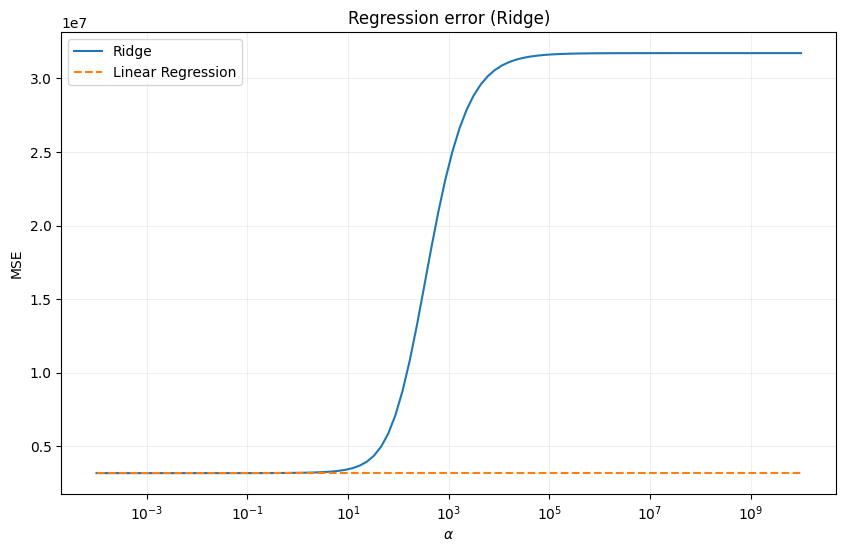

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(alphas, err_ridge, label='Ridge')
plt.plot(alphas, baseline, '--', label='Linear Regression')

plt.xscale('log')
plt.xlabel(r'$\alpha$')
plt.ylabel('MSE')
plt.title('Regression error (Ridge)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Como la regresión lineal no estaba en overfit no hay un alpha de ridge que reduzca el error de la regresión lineal.

In [24]:
print("Mínimo MSE Ridge:", min(err_ridge))
print("Mejor alpha Ridge:", alphas[np.argmin(err_ridge)])

Mínimo MSE Ridge: 3174099.280946134
Mejor alpha Ridge: 0.0001


Entonces el mejor alpha es el priemro por el que empezamos.

También vamos a estudiar cómo cambia el peso de cada variable al aumentar la regularización.

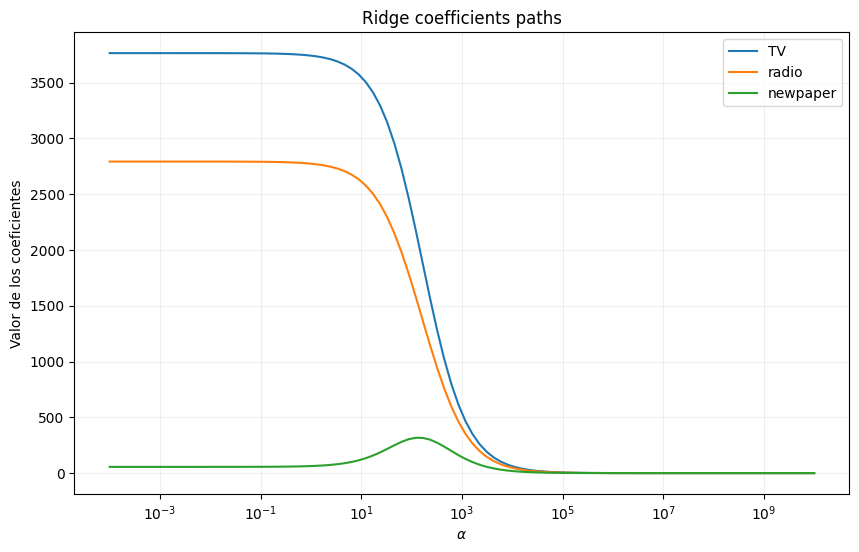

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(alphas, coef_ridge)

plt.xscale('log')
plt.xlabel(r'$\alpha$')
plt.ylabel('Valor de los coeficientes')
plt.title('Ridge coefficients paths')
plt.legend(X.columns)
plt.grid(alpha=0.2)
plt.show()

### Lasso

Buscamos el alpha que reduzca más el error

In [26]:
from sklearn.linear_model import Lasso
from sklearn import linear_model, metrics, model_selection
lasso = Lasso(fit_intercept=False)

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_train_scaled, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred_lasso = lasso.predict(X_test_scaled)
    lasso_error = metrics.mean_squared_error(y_pred_lasso, y_test)    
    err_lasso.append(lasso_error)





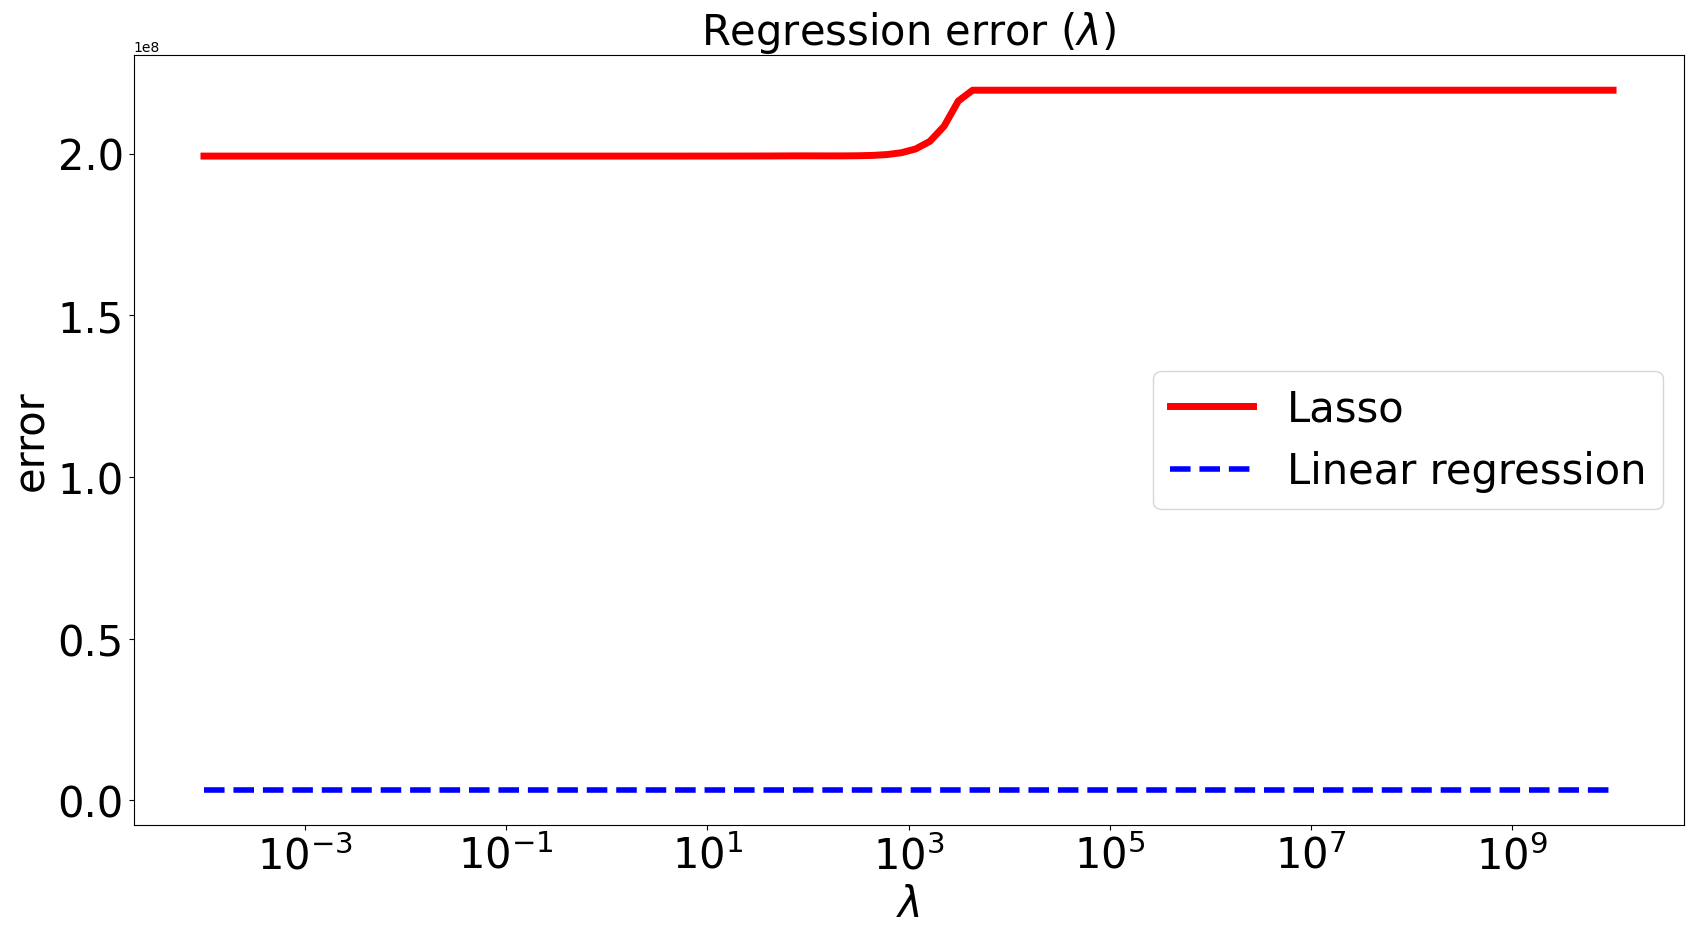

In [ ]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

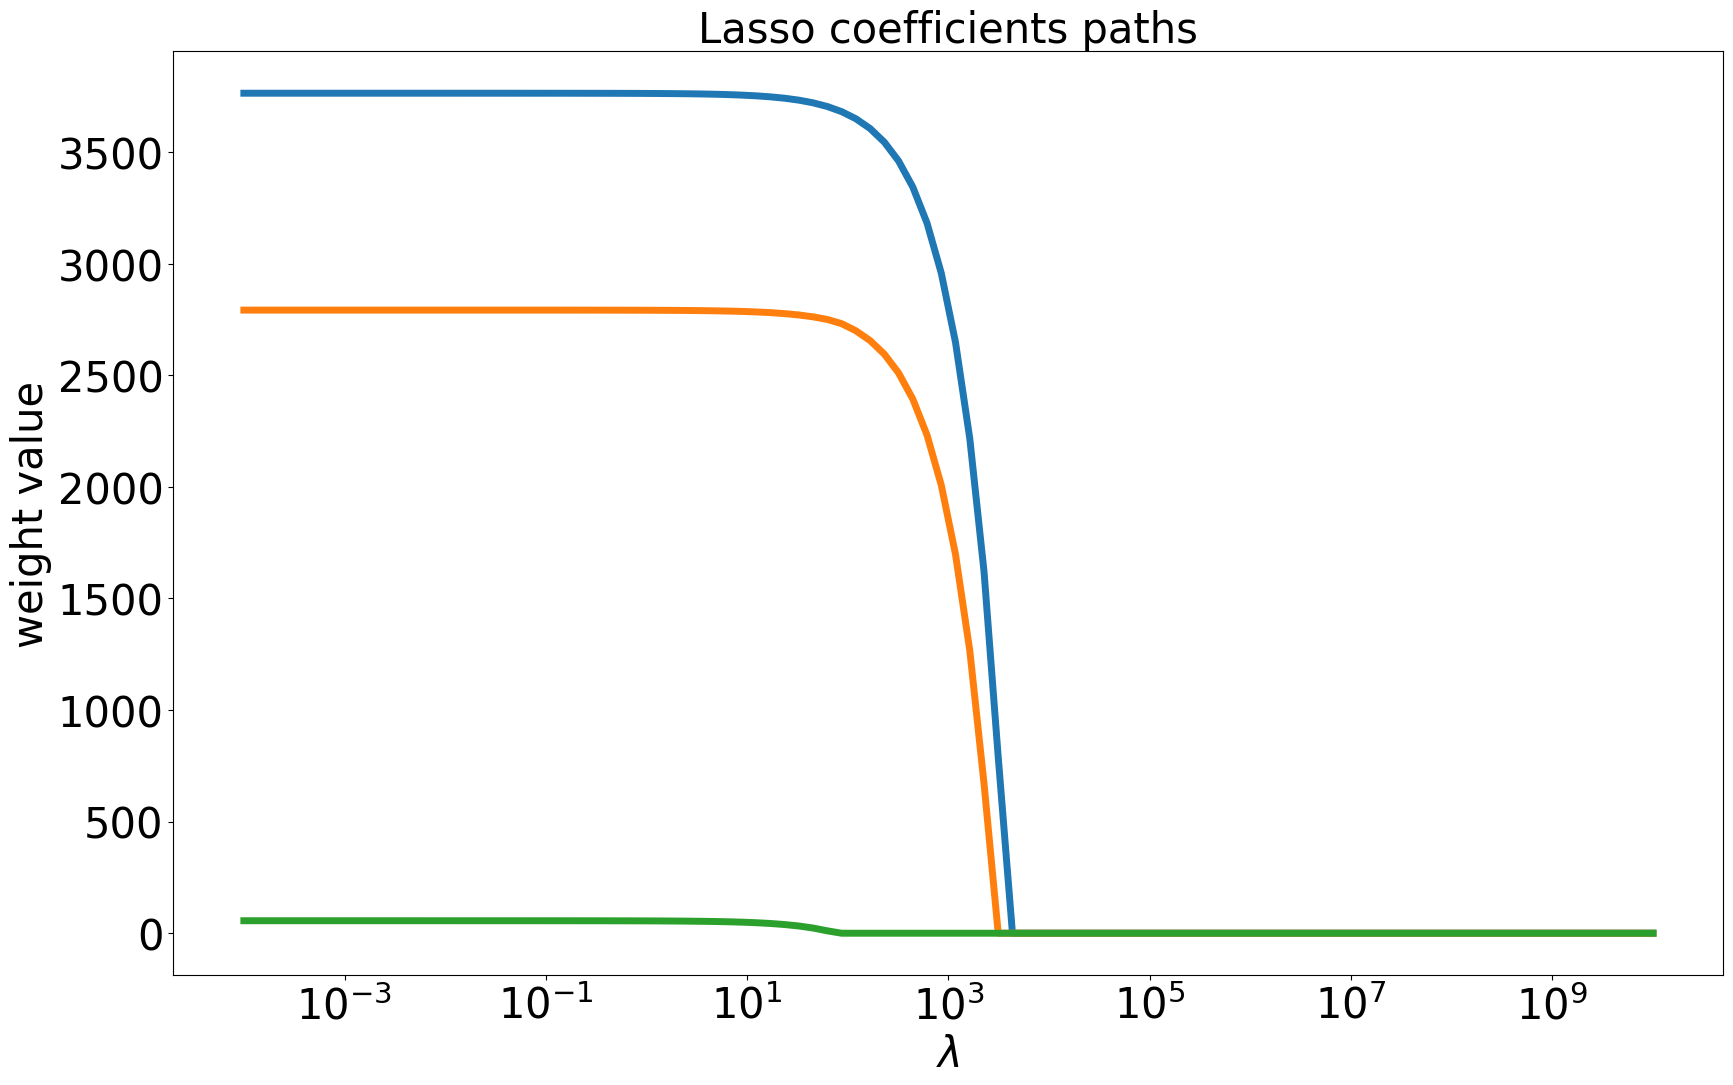

In [28]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, coef_lasso, linewidth=5)
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('weight value', fontsize=30)
plt.title('Lasso coefficients paths', fontsize=30)
plt.show()

In [29]:
from sklearn.linear_model import ElasticNet

### Elastic net

In [32]:
coef_eln = []
err_eln = []
baseline = []
for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_train_scaled, y_train)
    coef_eln.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test_scaled)
    elasticnet_error = metrics.mean_squared_error(y_pred, y_test)
    err_eln.append(elasticnet_error)
    baseline.append(baseline_error)

In [33]:
min(err_eln)

3174251.561251843

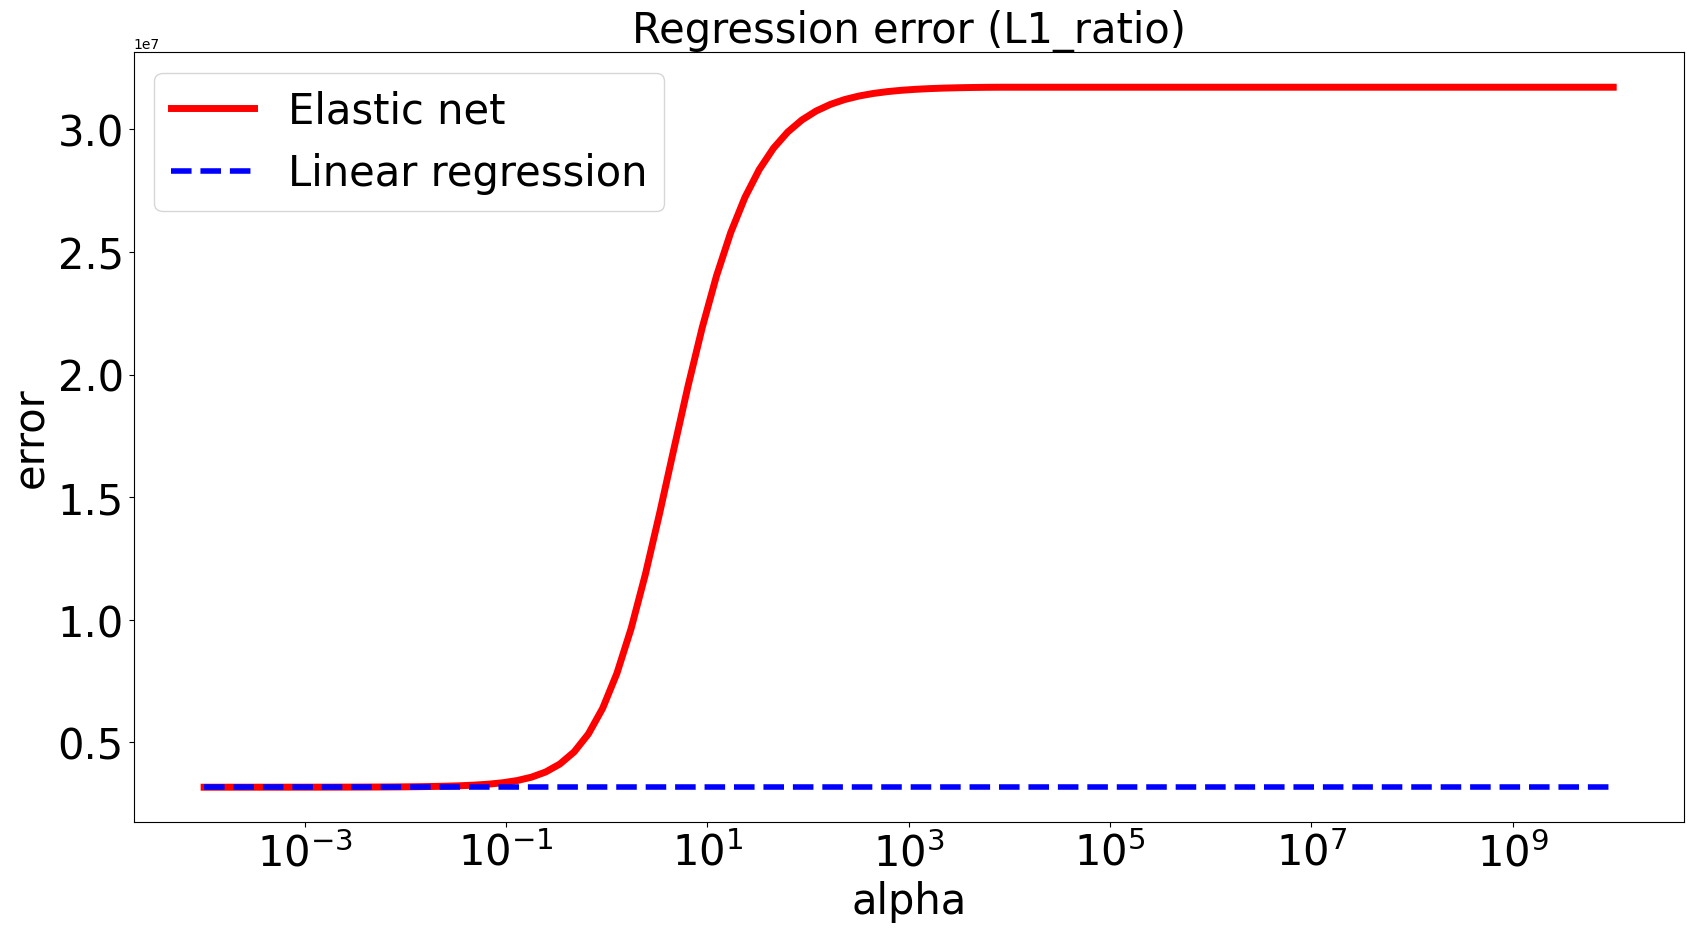

In [34]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()

In [35]:
print("Linear regression error:   %0.4f" % baseline_error)    
print("Minimun ridge error:       %0.4f" % min(err_ridge))
print("Minimum lasso error:       %0.4f" % min(err_lasso))
print("Minimum elastic net error: %0.4f" % min(err_eln))

Linear regression error:   3174097.3540
Minimun ridge error:       3174099.2809
Minimum lasso error:       199233999.5962
Minimum elastic net error: 3174251.5613


### Modelos Polinómicos

In [37]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Create polynomial features of degree 2
poly = PolynomialFeatures(degree=2)

# Transform training and testing data
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

In [38]:
# Create the polynomial regression model
lm_poly = LinearRegression()

# Train the model
lm_poly.fit(X_train_poly, y_train)

Y_train_pred_poly = lm_poly.predict(X_train_poly)
Y_test_pred_poly = lm_poly.predict(X_test_poly)

In [39]:
# Training performance
mse_train_poly = mean_squared_error(y_train, Y_train_pred_poly)
r2_train_poly = r2_score(y_train, Y_train_pred_poly)

# Testing performance
mse_test_poly = mean_squared_error(y_test, Y_test_pred_poly)
r2_test_poly = r2_score(y_test, Y_test_pred_poly)

print("Polynomial Regression - Training")
print("MSE:", mse_train_poly)
print("R2:", r2_train_poly)

print("\nPolynomial Regression - Testing")
print("MSE:", mse_test_poly)
print("R2:", r2_test_poly)

Polynomial Regression - Training
MSE: 360396.6744701222
R2: 0.986104518792419

Polynomial Regression - Testing
MSE: 412910.2285378997
R2: 0.9869181490609604


In [40]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split

# 1. Crear características polinómicas (grado 2 suele ser un buen punto de partida)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# 2. Dividir los datos polinómicos
X_train_p, X_test_p, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)

# 3. Escalar los datos
scaler = StandardScaler()
X_train_ps = scaler.fit_transform(X_train_p)
X_test_ps = scaler.transform(X_test_p)

In [41]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
import numpy as np

# Definir los posibles valores de alpha
alphas = np.logspace(-4, 4, 50)

# --- Modelo Ridge ---
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_ps, y_train)
y_pred_ridge = ridge_cv.predict(X_test_ps)

# --- Modelo Lasso ---
# Aumentamos max_iter porque Lasso puede tardar en converger con polinomios
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=100000)
lasso_cv.fit(X_train_ps, y_train)
y_pred_lasso = lasso_cv.predict(X_test_ps)

# --- Modelo ElasticNet ---
enet_cv = ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.99], cv=5, max_iter=100000)
enet_cv.fit(X_train_ps, y_train)
y_pred_enet = enet_cv.predict(X_test_ps)

# Evaluar utilizando tu función previa
print("Ridge Test:", evaluar_modelo(y_test, y_pred_ridge))
print("Lasso Test:", evaluar_modelo(y_test, y_pred_lasso))
print("ElasticNet Test:", evaluar_modelo(y_test, y_pred_enet))

Ridge Test: {'MAE': 519.1154185868456, 'MSE': 402914.8321947164, 'RMSE': np.float64(634.7557263977351), 'R2': 0.987234823911814}
Lasso Test: {'MAE': 490.35190568898304, 'MSE': 375895.4167388302, 'RMSE': np.float64(613.1031044928986), 'R2': 0.9880908549350839}
ElasticNet Test: {'MAE': 518.0266130324901, 'MSE': 401551.7278646047, 'RMSE': np.float64(633.6810931885254), 'R2': 0.9872780098791949}


In [42]:
feature_names = poly.get_feature_names_out(X.columns)
coeficientes = lasso_cv.coef_ # Cambia lasso_cv por tu mejor modelo
intercepto = lasso_cv.intercept_

formula = f"Ventas = {intercepto:.2f} "
for name, coef in zip(feature_names, coeficientes):
    if coef != 0: # Lasso hará cero muchos coeficientes
        formula += f"+ ({coef:.2f} * {name}) "
print("Fórmula:", formula)

Fórmula: Ventas = 14100.00 + (4182.26 * TV) + (302.16 * radio) + (138.52 * newpaper) + (-2600.60 * TV^2) + (3626.59 * TV radio) + (-208.31 * TV newpaper) + (68.42 * radio^2) + (127.08 * radio newpaper) 


## Resultados

In [269]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [ ]:
# El error más pequeño se obtiene haciendo la regresión lineal simple del principio.